In [1]:
from pathlib import Path
import os, sys, sqlite3, pandas as pd

PROSJEKT = Path.cwd()
if PROSJEKT.name == "notebooks":
    PROSJEKT = PROSJEKT.parent
os.chdir(PROSJEKT)
if str(PROSJEKT) not in sys.path:
    sys.path.insert(0, str(PROSJEKT))

from src.kunstpixel.core import db  # Ferdige fasit-kalkulatorer (lønn, overtid, sykefravær)

con = sqlite3.connect("file:05_data/museum.db?mode=ro", uri=True)   # mode=ro: kan ikke endre databasen
sql = lambda q: pd.read_sql(q, con)
sql("select name from sqlite_master where type='table' order by name")

,name
0,arbeidstid_grenser
1,arbeidstilsynet_renhold
2,avvik_hms_drift
3,dagsbesok
4,handbok_oppslag
5,hendelser
6,hms_ergonomi_rotasjon
7,hr_ansatte
8,hr_availability
9,hr_fravaer


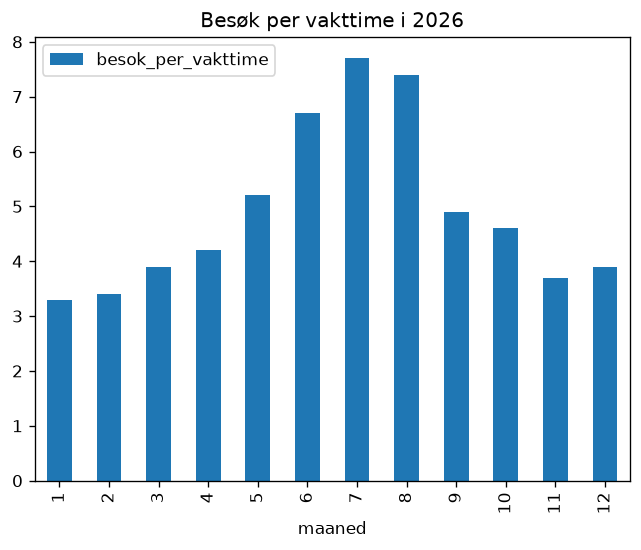

,maaned,besok,vakter,timer,besok_per_vakttime
0,1,6885,278,2101.5,3.3
1,2,6410,248,1883.0,3.4
2,3,7948,270,2048.5,3.9
3,4,8600,268,2044.5,4.2
4,5,11026,278,2102.5,5.2
5,6,13181,260,1968.5,6.7
6,7,16276,278,2103.5,7.7
7,8,15003,270,2040.0,7.4
8,9,10082,268,2046.5,4.9
9,10,9644,278,2105.5,4.6


In [2]:
df = sql("""
select d.maaned, sum(d.besok_totalt) as besok, v.vakter, v.timer
from dagsbesok d
join (select maaned, count(*) as vakter, sum(timer) as timer from hr_vakter where aar = 2026 group by maaned) v using (maaned)
where d.aar = 2026 and d.er_aapent = 1
group by d.maaned order by d.maaned
""")
df["besok_per_vakttime"] = (df.besok / df.timer).round(1)
df.plot(x="maaned", y="besok_per_vakttime", kind="bar", title="Besøk per vakttime i 2026")
df

In [3]:
# Bruker samme fasit-kalkulator som nettsiden (Datafinner), slik at kronebeløpene alltid er 100 % like
kost = db.query_shift_cost("2026-05")
df_kost = pd.DataFrame(kost["avdelinger"])
df_kost

,avdeling,vakter,timer,kveldstimer,vakter_uten_tariff,kostnad_nok
0,Formidling,145,1098.5,18.5,0,508364.25
1,Marked,71,536.5,20.0,0,252134.62
2,Drift,40,300.0,49.5,0,146088.36
3,Samling,22,167.5,3.0,0,77209.03
